# PREDICT/90 Pro - Football Match Predictor

Home / Draw / Away probabilities for **38 leagues**, **cups** and **national teams**, plus Over/Under 2.5, BTTS, value bets, Kelly stakes,
corners, cards, shots, 4 daily accas, predictions by strength, injuries and a bet tracker. Every number below is built only from information known **before kickoff**.

**Run it:** menu *Run -> Run All* (Jupyter) or *Runtime -> Run all* (Google Colab).

| Part | What you get |
|---|---|
| 1 | Setup (PC or Colab) |
| 2 | Today's and tomorrow's predictions -> also saved to Excel |
| 3 | Injuries and lineups |
| 4 | Backtest: how good is it really, season by season |
| 5 | Goals, corners, cards and shots |
| 5b | National teams: the test |
| 5c | Bangers by market and the mixed acca: the test |
| 5d | Cups: the test |
| 6 | Value bets and profit vs bookmakers |
| 7 | The accas - tested on the past |
| 8 | Your bet tracker |
| 9 | How it works and why each part was chosen |
| 10 | Tune the models again (optional) |
| 11 | Honest notes, and what differs from the plan |

Data: football-data.co.uk (results + odds, free), API-Football (fixtures, odds, injuries, lineups - free plan).
Models: Logistic Regression + XGBoost + LightGBM + Neural Network, stacked, tuned with Optuna.

## 1. Setup

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # Colab: the newest code comes from GitHub, your own files (tracker, models, key, settings) stay in your Google Drive
    import glob, shutil, zipfile, urllib.request, importlib.util, importlib.metadata
    CODE_URL = "https://github.com/RicardoJose000/predict90-colab/archive/refs/heads/main.zip"
    if int(importlib.metadata.version("pandas").split(".")[0]) >= 3:          # the code is made for pandas 2
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas>=2.2.3,<3"], check=True)
        print("Colab restarts once now. Wait a few seconds, then press Runtime -> Run all again.")
        os.kill(os.getpid(), 9)
    missing = [p for p in ("optuna", "openpyxl", "lightgbm", "xgboost") if importlib.util.find_spec(p) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    PROJECT = "/content/Football_Predictor_Pro"
    if not os.path.isdir(os.path.join(PROJECT, "p90")):
        print("Downloading the code ...")
        urllib.request.urlretrieve(CODE_URL, "/content/code.zip")
        shutil.rmtree("/content/code", ignore_errors=True)
        with zipfile.ZipFile("/content/code.zip") as z:
            z.extractall("/content/code")
        shutil.move(glob.glob("/content/code/*")[0], PROJECT)
    FILES = "/content/my_files"
    try:
        from google.colab import drive
        drive.mount("/content/drive")      # Colab asks you to allow Google Drive: press Connect / Allow
        FILES = "/content/drive/MyDrive/Football_Predictor_files"
    except Exception as e:
        print(f"Google Drive is not connected ({e}). It still works, but the tracker and models are lost when Colab closes.")
    for f in ("settings.json", "models/best_params.json", "output/backtest_predictions.csv.gz",
              "output/backtest_more_bets.csv.gz", "output/combination_test.csv", "output/backtest_internationals.csv.gz"):
        src, dst = os.path.join(PROJECT, f), os.path.join(FILES, f)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        if os.path.exists(src) and (not os.path.exists(dst) or (f.startswith("output/") and os.path.getsize(src) != os.path.getsize(dst))):
            shutil.copy(src, dst)          # your settings are kept, the test results are always the newest
    os.environ["P90_FILES"] = FILES
    os.chdir(PROJECT)
sys.path.insert(0, os.getcwd())

API_FOOTBALL_KEY = ""   # optional: paste your free API-Football key here ONE time - it is saved to .env
if API_FOOTBALL_KEY:
    open(os.path.join(os.environ.get("P90_FILES", "."), ".env"), "w").write(f"API_FOOTBALL_KEY={API_FOOTBALL_KEY.strip()}\n")

import numpy as np, pandas as pd
from IPython.display import display, Markdown
from p90 import pipeline, evaluate, charts, config, props, tracker, live, intl, bangers, cups
from p90.config import MAIN_LEAGUES, league_label

S = config.load_settings()
print(f"Folder : {os.path.basename(os.getcwd())} | your files: {config.FILES.name}")
print(f"Leagues: {len(S['leagues'])}")
print(f"API-Football key: {'found' if config.api_key() else 'not set (injuries + extra fixtures are skipped)'}")
import numpy, scipy, sklearn, lightgbm, xgboost
print(f"Versions: Python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {numpy.__version__}, scikit-learn {sklearn.__version__}, LightGBM {lightgbm.__version__}, XGBoost {xgboost.__version__}")

NAMES = {"fold": "Season", "matches": "Matches", "accuracy": "Model", "accuracy_bookie": "Bookmaker", "logloss": "Log-loss",
         "logloss_bookie": "Log-loss bookmaker", "conf_acc": "Picks 50%+", "conf_share": "Share 50%+", "strong_acc": "Picks 65%+",
         "strong_share": "Share 65%+", "strong_n": "Number 65%+", "threshold": "At least this sure", "share": "Share of matches",
         "predicted": "Model said", "actual": "Really happened", "n": "Outcomes", "bin": "Range", "league": "Code", "name": "League",
         "min_edge": "Min edge", "bets": "Bets", "hit": "Hit rate", "avg_odds": "Avg odds", "roi": "ROI", "slips": "Slips",
         "break_even": "Break-even", "said": "Model said", "real": "Really happened", "legs": "Legs", "pick": "Bet"}
PCT = {"Home %", "Draw %", "Away %", "Pick %", "Over 2.5 %", "BTTS %", "Edge %", "Model", "Bookmaker", "Picks 50%+", "Share 50%+",
       "Picks 65%+", "Share 65%+", "At least this sure", "Share of matches", "Model said", "Really happened", "Min edge",
       "Hit rate", "ROI", "Break-even", "Accuracy", "Always pick the most common", "65%+ picks accuracy",
       "Happened", "Share", "Right", "Model said (60%+)", "Always likelier side", "Lowest season",
       "Bet365", "Best odds", "2018-21", "2022 on", "Higher rated wins", "Picks 75%+", "Share 75%+", "Share 60%+",
       "Won", "Profit per slip", "Stronger club wins", "Only 1 leg lost", "Legs right", "Picks 65%+"}
def show(df, n=None):
    """Pretty table: friendly names, percentages as %, odds with 2 decimals."""
    if df is None or len(df) == 0:
        print("(nothing to show)"); return
    d = (df.head(n) if n else df).rename(columns=NAMES)
    fmt = {c: "{:.1%}" for c in d.columns if c in PCT}
    fmt.update({c: "{:.2f}" for c in d.columns if ("odds" in str(c).lower() or c == "Stake") and c not in PCT})
    fmt.update({c: "{:.2f}" for c in d.columns if c in ("Staked", "Profit")})
    fmt.update({c: "{:.4f}" for c in d.columns if "Log-loss" in str(c)})
    fmt.update({c: "{:,.0f}" for c in d.columns if c in ("Matches", "Bets", "Slips", "Outcomes", "Number 65%+", "65%+ picks", "60%+ picks")})
    fmt.update({"Slips a day": "{:.1f}"} if "Slips a day" in d.columns else {})
    fmt.update({c: "{:,.0f}" for c in ("Picks", "Per season", "Real odds slips") if c in d.columns})
    fmt.update({"Legs (avg)": "{:.1f}"} if "Legs (avg)" in d.columns else {})
    fmt.update({"Expected": "{:.1f}"} if "Expected" in d.columns else {})
    fmt.update({"Legs": "{:.1f}"} if "Legs" in d.columns and d["Legs"].dtype == float else {})
    fmt.update({"Pick %": "{:.1%}"} if "Pick %" in d.columns else {})
    fmt = {c: f for c, f in fmt.items() if pd.api.types.is_numeric_dtype(d[c])}   # text columns stay as they are
    display(d.style.format(fmt, na_rep="").hide(axis="index"))

Folder : Football_Predictor_Pro | your files: Football_Predictor_Pro
Leagues: 38
API-Football key: found
Versions: Python 3.13.1, pandas 2.2.3, numpy 2.1.3, scikit-learn 1.6.1, LightGBM 4.6.0, XGBoost 2.1.4


## 2. Today's and tomorrow's predictions

One call does everything: download the newest results and odds -> upcoming matches -> features ->
models (trained again automatically every 7 days) -> probabilities -> value bets -> accas -> Excel file in `output/`.

In [2]:
out = pipeline.daily()
T = pipeline.tables(out) if len(out.get('predictions', [])) else {}

1/5 Results and odds for 38 leagues


  228,543 finished matches, 38 leagues, 29 Jul 2005 to 09 Nov 2026 (16s)
2/5 Upcoming matches


  football-data.co.uk: 0 upcoming matches with odds


  API-Football: 50 matches today/tomorrow in your leagues


  ! API-Football daily limit reached: some odds and injuries are missing today
  API-Football requests used now: 1, daily limit reached


  ! API-Football daily limit reached: some odds and injuries are missing today
  internationals: 7 newest results added from API-Football


... (4 outputs left out)

  using models trained 09 Nov 2026 13:41 (retrain every 7 days)


5/5 Predictions



Saved: predictions_2026-11-13.xlsx and predictions_2026-11-13.html in the output folder


Done in 167s: 119 matches, 13 bangers, 15 strong, 0 value bets, accas: 2 main, 2 strong, 1 banger, 5 other, 3 my picks, 6 banger accas by market, 2 mixed | 58 national team matches, 1 international accas | 11 cup matches, 0 cup accas


### The results page

The same results as the Excel file, as one page with tabs and filters. It works on a phone, right here in the notebook.
It is also saved in the `output` folder as `predictions_...html`: on a PC it opens by itself after `RUN_ME.bat`.

In [3]:
if out.get("page"):
    from html import escape
    from IPython.display import HTML
    display(HTML('<div><iframe srcdoc="' + escape(out["page"].read_text(encoding="utf-8")) + '" style="width:100%;height:760px;border:0;border-radius:12px" title="Results page"></iframe></div>'))

### Predictions by strength

**Banger** = pick is 75%+, **Strong** = 65-75%, **Good** = 50-65%, **Weak** = below 50%. The test of each group is in part 4.
In the Excel file and the page `All`, `Bangers`, `Strong` and `Weak` each have their own tab, and you can filter them by day and league, also by `League type` (Main or Other).

In [4]:
PICK_COLS = ["Date","Time","League","League type","Home","Away","Pick","Pick %","Home %","Draw %","Away %","Odds 1","Odds X","Odds 2"]
print("Bangers (75%+)")
show(T.get("Bangers", pd.DataFrame()).reindex(columns=PICK_COLS))
print("Strong (65-75%)")
show(T.get("Strong", pd.DataFrame()).reindex(columns=PICK_COLS))

Bangers (75%+)


Date,Time,League,League type,Home,Away,Pick,Pick %,Home %,Draw %,Away %,Odds 1,Odds X,Odds 2
Fri 13 Nov,21:00,International - AFCON qualifiers,International,Morocco,Niger,Home,91.3%,91.3%,7.5%,1.2%,1.07,9.50,26.00
Sat 14 Nov,10:00,International - Other tournaments,International,India,Bhutan,Home,90.6%,90.6%,7.2%,2.1%,,,
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Angola,South Sudan,Home,89.2%,89.2%,8.8%,2.0%,1.09,8.50,23.00
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Nigeria,Tanzania,Home,89.0%,89.0%,8.8%,2.2%,1.18,7.50,9.50
Fri 13 Nov,20:00,International - AFCON qualifiers,International,Egypt,Malawi,Home,88.0%,88.0%,9.8%,2.2%,1.09,8.00,26.00
Fri 13 Nov,20:00,International - CONCACAF Nations League,International,Puerto Rico,Dominica,Home,83.1%,83.1%,11.5%,5.4%,,,
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Algeria,Togo,Home,83.1%,83.1%,13.5%,3.5%,1.20,5.25,15.00
Fri 13 Nov,17:00,International - AFCON qualifiers,International,South Africa,Kenya,Home,79.2%,79.2%,16.0%,4.8%,1.25,5.00,10.00
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Cape Verde,Liberia,Home,77.9%,77.9%,15.3%,6.8%,1.22,5.25,9.50
Sat 14 Nov,16:00,Scotland - Championship,Main,Livingston,Morton,Home,77.4%,77.4%,15.3%,7.3%,1.25,5.00,10.00


Strong (65-75%)


Date,Time,League,League type,Home,Away,Pick,Pick %,Home %,Draw %,Away %,Odds 1,Odds X,Odds 2
Fri 13 Nov,21:00,Cup - Spain Copa del Rey,Cup,Salamanca UDS,Celta,Away,74.8%,9.7%,15.5%,74.8%,,,
Sat 14 Nov,17:00,International - AFCON qualifiers,International,Uganda,Botswana,Home,73.1%,73.1%,18.6%,8.3%,1.53,3.50,7.00
Fri 13 Nov,14:00,International - AFCON qualifiers,International,Comoros,Congo,Home,72.9%,72.9%,19.1%,8.0%,1.75,3.40,4.33
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Burkina Faso,Mauritania,Home,72.0%,72.0%,18.5%,9.5%,1.53,3.50,6.50
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Gabon,Lesotho,Home,70.6%,70.6%,19.3%,10.2%,1.25,5.50,10.00
Sat 14 Nov,16:00,England - National League,Main,Carlisle,Boston Utd,Home,69.3%,69.3%,18.2%,12.6%,,,
Fri 13 Nov,14:00,International - AFCON qualifiers,International,Zambia,Burundi,Home,69.0%,69.0%,19.1%,11.9%,1.55,3.40,6.25
Sat 14 Nov,16:00,England - National League,Main,Southend,Aldershot,Home,68.3%,68.3%,18.3%,13.4%,,,
Fri 13 Nov,14:00,International - AFCON qualifiers,International,Mozambique,Ethiopia,Home,67.6%,67.6%,21.0%,11.4%,1.57,3.50,6.00
Sat 14 Nov,18:00,International - UEFA Nations League,International,Norway,Wales,Home,67.4%,67.4%,20.1%,12.5%,1.22,7.00,10.00


### Value bets
Our chance x the odds beats 1.05. *Stake* = quarter-Kelly on the bankroll in `settings.json`.

In [5]:
show(T.get("Value bets"))

(nothing to show)


### My picks

My own recommendation: 1 long acca around 5 odds and up to 2 safer accas around 2.3 odds, only when the model has them. No match is used twice. Part 7 has the test of this exact rule: about break-even, not a sure profit.

In [6]:
show(T.get("My picks"))

Row,Set,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,Long acca: banger,2026-11-13,1,5 legs,,,,28.2%,5.45,
,,,1,Comoros v Congo (14:00),International - AFCON qualifiers,International,Home win,72.9%,1.75,
,,,1,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Home win,89.0%,1.18,
,,,1,Burkina Faso v Mauritania (17:00),International - AFCON qualifiers,International,Home win,72.0%,1.53,
,,,1,Slovakia v Faroe Islands (20:45),International - UEFA Nations League,International,Home win,76.1%,1.38,
,,,1,South Africa v Kenya (17:00),International - AFCON qualifiers,International,Home win,79.2%,1.25,
SLIP,Safer acca,2026-11-13,2,4 legs,,,,32.3%,2.48,
,,,2,Mali v Rwanda (20:00),International - AFCON qualifiers,International,Home win,76.6%,1.28,
,,,2,Liechtenstein v Azerbaijan (20:45),International - UEFA Nations League,International,Away win,76.8%,1.27,
,,,2,Cape Verde v Liberia (17:00),International - AFCON qualifiers,International,Home win,77.9%,1.22,


### Bangers by market

The safest pick of each kind, only 75%+: 1X2, Over 2.5, Over 1.5, corners, cards and shots. A match in Over 2.5 is not shown again in Over 1.5.
Corners, cards and shots show every match once, at its highest line that is still 75%+. No BTTS: the model never reaches 75% for it.
Then one acca per market and day (total odds about 2 to 3): one market per slip, so the same match is never twice in a slip. Part 5c has the test.

In [7]:
for name in ["1X2", "Over 2.5 goals", "Over 1.5 goals", "Corners over", "Cards over", "Shots over"]:
    t = T.get(name, pd.DataFrame())
    print(f"{name}: {len(t)} picks")
    show(t, 10)
print("Banger accas")
show(T.get("Banger accas"))

1X2: 12 picks


Date,Time,League,League type,Home,Away,Pick,Pick %,Odds,Price
Fri 13 Nov,21:00,International - AFCON qualifiers,International,Morocco,Niger,Morocco win,91.3%,1.07,
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Angola,South Sudan,Angola win,89.2%,1.09,
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Nigeria,Tanzania,Nigeria win,89.0%,1.18,
Fri 13 Nov,20:00,International - AFCON qualifiers,International,Egypt,Malawi,Egypt win,88.0%,1.09,
Fri 13 Nov,20:00,International - CONCACAF Nations League,International,Puerto Rico,Dominica,Puerto Rico win,83.1%,1.12,estimate
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Algeria,Togo,Algeria win,83.1%,1.20,
Fri 13 Nov,17:00,International - AFCON qualifiers,International,South Africa,Kenya,South Africa win,79.2%,1.25,
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Cape Verde,Liberia,Cape Verde win,77.9%,1.22,
Sat 14 Nov,16:00,Scotland - Championship,Main,Livingston,Morton,Livingston win,77.4%,1.25,
Fri 13 Nov,20:45,International - UEFA Nations League,International,Liechtenstein,Azerbaijan,Azerbaijan win,76.8%,1.27,


Over 2.5 goals: 0 picks
(nothing to show)
Over 1.5 goals: 72 picks


Date,Time,League,League type,Home,Away,Pick,Pick %,Odds,Price
Fri 13 Nov,21:00,International - AFCON qualifiers,International,Morocco,Niger,Over 1.5,88.1%,1.14,
Sat 14 Nov,16:00,England - National League,Main,Yeovil,Boreham Wood,Over 1.5,85.1%,1.10,estimate
Sun 15 Nov,00:30,Brazil - Serie A,Other,Chapecoense-SC,Vasco,Over 1.5,84.8%,1.20,
Fri 13 Nov,20:00,International - CONCACAF Nations League,International,Puerto Rico,Dominica,Over 1.5,84.5%,1.11,estimate
Sat 14 Nov,16:00,Scotland - Championship,Main,Livingston,Morton,Over 1.5,84.3%,1.17,
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Angola,South Sudan,Over 1.5,84.3%,1.20,
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Nigeria,Tanzania,Over 1.5,84.2%,1.22,
Sat 14 Nov,16:00,Scotland - League Two,Main,Stirling,Elgin,Over 1.5,83.3%,1.12,estimate
Sat 14 Nov,16:00,England - National League,Main,Harrogate,Altrincham,Over 1.5,83.3%,1.12,estimate
Sat 14 Nov,16:00,England - National League,Main,Southend,Aldershot,Over 1.5,83.3%,1.12,estimate


Corners over: 47 picks


Date,Time,League,League type,Home,Away,Pick,Expected,Pick %,Odds,Price
Sat 14 Nov,16:00,England - National League,Main,Hartlepool,Wealdstone,Corners over 6.5,9.9,84.3%,1.11,estimate
Sat 14 Nov,18:30,England - League Two,Main,Fleetwood Town,Tranmere,Corners over 6.5,9.8,84.1%,1.11,estimate
Sat 14 Nov,16:00,England - League Two,Main,Shrewsbury,Oldham,Corners over 6.5,9.8,84.0%,1.11,estimate
Sat 14 Nov,16:00,Scotland - Championship,Main,Livingston,Morton,Corners over 6.5,9.8,83.9%,1.11,estimate
Sat 14 Nov,16:00,England - League Two,Main,Salford,Northampton,Corners over 6.5,9.8,83.9%,1.11,estimate
Sat 14 Nov,16:00,England - League One,Main,AFC Wimbledon,Blackpool,Corners over 7.5,11.0,83.9%,1.11,estimate
Sat 14 Nov,16:00,England - League Two,Main,Port Vale,Accrington,Corners over 6.5,9.8,83.7%,1.12,estimate
Sat 14 Nov,16:00,Scotland - League Two,Main,Kelty Hearts,Stranraer,Corners over 6.5,9.8,83.7%,1.12,estimate
Sat 14 Nov,16:00,Scotland - League Two,Main,Edinburgh City,Clyde,Corners over 6.5,9.7,83.3%,1.12,estimate
Sat 14 Nov,13:30,England - League Two,Main,Exeter,Cheltenham,Corners over 6.5,9.7,83.2%,1.12,estimate


... (2 outputs left out)

Shots over: 32 picks


Date,Time,League,League type,Home,Away,Pick,Expected,Pick %,Odds,Price
Sat 14 Nov,16:00,Scotland - League Two,Main,Stirling,Elgin,Shots over 15.5,20.0,81.0%,1.15,estimate
Sat 14 Nov,16:00,England - National League,Main,Carlisle,Boston Utd,Shots over 15.5,19.9,80.5%,1.16,estimate
Sat 14 Nov,16:00,England - League Two,Main,Port Vale,Accrington,Shots over 20.5,25.5,80.2%,1.17,estimate
Fri 13 Nov,20:30,Spain - Segunda Division,Main,Leganes,Burgos,Shots over 20.5,25.5,80.0%,1.17,estimate
Sat 14 Nov,16:00,England - League One,Main,Wigan,Barnsley,Shots over 22.5,27.7,79.9%,1.17,estimate
Sat 14 Nov,16:00,England - National League,Main,Southend,Aldershot,Shots over 16.5,20.9,79.7%,1.17,estimate
Sat 14 Nov,16:15,Spain - Segunda Division,Main,Sociedad B,Sp Gijon,Shots over 22.5,27.7,79.6%,1.17,estimate
Sat 14 Nov,16:00,England - National League,Main,Harrogate,Altrincham,Shots over 15.5,19.7,79.5%,1.18,estimate
Sat 14 Nov,18:30,England - League Two,Main,Fleetwood Town,Tranmere,Shots over 22.5,27.6,79.3%,1.18,estimate
Sat 14 Nov,14:00,Spain - Segunda Division,Main,Valladolid,Castellon,Shots over 21.5,26.4,79.1%,1.18,estimate


Banger accas


Row,Set,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,1X2 acca,2026-11-13,1,3 legs,,,,53.6%,2.04,
,,,1,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Home win,89.0%,1.18,
,,,1,Slovakia v Faroe Islands (20:45),International - UEFA Nations League,International,Home win,76.1%,1.38,
,,,1,South Africa v Kenya (17:00),International - AFCON qualifiers,International,Home win,79.2%,1.25,
SLIP,Over 1.5 goals acca,2026-11-13,2,3 legs,,,,47.5%,2.03,
,,,2,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Over 1.5,84.2%,1.22,
,,,2,Liechtenstein v Azerbaijan (20:45),International - UEFA Nations League,International,Over 1.5,75.1%,1.30,
,,,2,Cape Verde v Liberia (17:00),International - AFCON qualifiers,International,Over 1.5,75.0%,1.28,
SLIP,Over 1.5 goals acca,2026-11-14,1,4 legs,,,,43.5%,2.19,
,,,1,Angola v South Sudan (20:00),International - AFCON qualifiers,International,Over 1.5,84.3%,1.20,


### Mixed acca

One acca a day from the bangers of every kind: the top 2 of 1X2, Over 2.5, Over 1.5, corners, cards and shots (`mixed_acca_per_market`), safest first, every match only once. Part 5c has the test.

In [8]:
show(T.get("Mixed acca"))

Row,Set,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,Mixed acca,2026-11-13,1,5 legs,,,,36.7%,2.39,has estimates
,,,1,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Home win,89.0%,1.18,
,,,1,South Africa v Kenya (17:00),International - AFCON qualifiers,International,Home win,79.2%,1.25,
,,,1,Grenada v Saint Kitts and Nevis (21:00),International - CONCACAF Nations League,International,Over 1.5,80.9%,1.16,estimate
,,,1,Egypt v Malawi (20:00),International - AFCON qualifiers,International,Over 1.5,80.3%,1.20,
,,,1,Leganes v Burgos (20:30),Spain - Segunda Division,Main,Shots over 20.5,80.0%,1.17,estimate
SLIP,Mixed acca,2026-11-14,1,9 legs,,,,16.0%,4.13,has estimates
,,,1,Algeria v Togo (20:00),International - AFCON qualifiers,International,Home win,83.1%,1.20,
,,,1,Livingston v Morton (16:00),Scotland - Championship,Main,Over 1.5,84.3%,1.17,
,,,1,Angola v South Sudan (20:00),International - AFCON qualifiers,International,Over 1.5,84.3%,1.20,


### The 4 accas

The `SLIP` row shows total odds and the chance that every leg wins. Within one sheet every match is used once. Part 7 has the test of each.

**Main acca**: win, double chance and over/under 2.5. These have old odds, so their profit is tested.

In [9]:
show(T.get("Main acca"))

Row,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,2026-11-14,1,4 legs,,,,15.7%,5.80,
,,1,Airdrie Utd v Queen of Sth (16:00),Scotland - League One,Main,Home win,61.1%,1.60,
,,1,Valladolid v Castellon (14:00),Spain - Segunda Division,Main,Draw or away,72.5%,1.36,
,,1,Cove Rangers v Montrose (16:00),Scotland - League One,Main,Over 2.5,52.3%,1.85,
,,1,East Fife v Peterhead (16:00),Scotland - League One,Main,Draw or away,67.6%,1.44,
SLIP,2026-11-14,2,3 legs,,,,17.2%,5.09,
,,2,Exeter v Cheltenham (13:30),England - League Two,Main,Home win,50.5%,1.90,
,,2,Livingston v Morton (16:00),Scotland - Championship,Main,Over 2.5,62.8%,1.53,
,,2,Partick v Inverness C (16:00),Scotland - Championship,Main,Home win,54.0%,1.75,


**Strong acca**: favourites to win only, every leg 65%+. Only 1 or 2 a day and only on some days. A small profit in the test, not proven.

In [10]:
show(T.get("Strong acca"))

Row,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,2026-11-13,1,4 legs,,,,32.2%,4.90,
,,1,Comoros v Congo (14:00),International - AFCON qualifiers,International,Home win,72.9%,1.75,
,,1,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Home win,89.0%,1.18,
,,1,Burkina Faso v Mauritania (17:00),International - AFCON qualifiers,International,Home win,72.0%,1.53,
,,1,Zambia v Burundi (14:00),International - AFCON qualifiers,International,Home win,69.0%,1.55,
SLIP,2026-11-13,2,6 legs,,,,18.7%,5.37,
,,2,Slovakia v Faroe Islands (20:45),International - UEFA Nations League,International,Home win,76.1%,1.38,
,,2,Mozambique v Ethiopia (14:00),International - AFCON qualifiers,International,Home win,67.6%,1.57,
,,2,South Africa v Kenya (17:00),International - AFCON qualifiers,International,Home win,79.2%,1.25,
,,2,Mali v Rwanda (20:00),International - AFCON qualifiers,International,Home win,76.6%,1.28,


**Banger acca**: favourites to win only, every leg 70%+. Very few, about 40 a season. A small profit in the test, not proven: read part 7 first.

In [11]:
show(T.get("Banger acca"))

Row,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,2026-11-13,1,5 legs,,,,28.2%,5.45,
,,1,Comoros v Congo (14:00),International - AFCON qualifiers,International,Home win,72.9%,1.75,
,,1,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Home win,89.0%,1.18,
,,1,Burkina Faso v Mauritania (17:00),International - AFCON qualifiers,International,Home win,72.0%,1.53,
,,1,Slovakia v Faroe Islands (20:45),International - UEFA Nations League,International,Home win,76.1%,1.38,
,,1,South Africa v Kenya (17:00),International - AFCON qualifiers,International,Home win,79.2%,1.25,


**Other acca**: bets with no old odds, so accuracy is tested but profit is not. `Price = estimate` means no real odds were found: only bets 60%+ sure are used then. Check the real price at your bookmaker before you bet.

In [12]:
show(T.get("Other acca"))

Row,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,2026-11-14,1,3 legs,,,,19.3%,5.32,
,,1,Exeter v Cheltenham (13:30),England - League Two,Main,Home cards under 2.5,67.4%,1.53,
,,1,Livingston v Morton (16:00),Scotland - Championship,Main,Corners under 10.5,56.4%,1.82,
,,1,Stenhousemuir v Queens Park (16:00),Scotland - Championship,Main,BTTS yes,50.8%,1.91,
SLIP,2026-11-14,2,3 legs,,,,17.7%,5.00,
,,2,Cove Rangers v Montrose (16:00),Scotland - League One,Main,Corners over 8.5,56.3%,1.73,
,,2,Airdrie Utd v Queen of Sth (16:00),Scotland - League One,Main,BTTS yes,57.4%,1.67,
,,2,Partick v Inverness C (16:00),Scotland - Championship,Main,BTTS yes,54.7%,1.73,
SLIP,2026-11-14,3,3 legs,,,,16.7%,4.93,has estimates
,,3,Valladolid v Castellon (14:00),Spain - Segunda Division,Main,Away corners under 4.5,51.2%,1.83,


**International acca**: national teams, favourites to win only, competitive matches only (no friendlies), every leg 70%+. Their accuracy is tested in part 5b. Their profit is not: the free data has no old odds for national teams.

In [13]:
show(T.get("International acca"))

Row,Day,Slip,Match,League,League type,Pick,Pick %,Odds,Price
SLIP,2026-11-13,1,5 legs,,,,28.2%,5.45,
,,1,Comoros v Congo (14:00),International - AFCON qualifiers,International,Home win,72.9%,1.75,
,,1,Nigeria v Tanzania (17:00),International - AFCON qualifiers,International,Home win,89.0%,1.18,
,,1,Burkina Faso v Mauritania (17:00),International - AFCON qualifiers,International,Home win,72.0%,1.53,
,,1,Slovakia v Faroe Islands (20:45),International - UEFA Nations League,International,Home win,76.1%,1.38,
,,1,South Africa v Kenya (17:00),International - AFCON qualifiers,International,Home win,79.2%,1.25,


**Cup acca**: cup favourites to win only, every leg 70%+. Accuracy is tested in part 5d, profit is not: the free data has no old cup odds.

In [14]:
show(T.get("Cup acca"))

(nothing to show)


### Cups

Champions League, Europa League, Conference League and the big domestic cups, today and tomorrow (needs the API-Football key).
Their own model on the clubs' league form. A European pick is never BANGER: the test (part 5d) showed those 75%+ picks right only 71% of the time.

In [15]:
show(T.get("Cups", pd.DataFrame()).reindex(columns=PICK_COLS + ["Strength", "Over 2.5 %", "BTTS %"]))

Date,Time,League,League type,Home,Away,Pick,Pick %,Home %,Draw %,Away %,Odds 1,Odds X,Odds 2,Strength,Over 2.5 %,BTTS %
Fri 13 Nov,21:00,Cup - Spain Copa del Rey,Cup,Salamanca UDS,Celta,Away,74.8%,9.7%,15.5%,74.8%,,,,STRONG,62.6%,44.3%
Sat 14 Nov,14:00,Cup - France Coupe de France,Cup,Tourcoing,Reims,Away,67.1%,14.5%,18.4%,67.1%,,,,STRONG,61.3%,49.6%
Sat 14 Nov,14:00,Cup - France Coupe de France,Cup,Balagne,Montpellier,Away,66.3%,14.9%,18.8%,66.3%,,,,STRONG,62.2%,51.5%
Sat 14 Nov,18:00,Cup - France Coupe de France,Cup,Stade Béthunois,Nancy,Away,60.2%,17.8%,22.0%,60.2%,,,,GOOD,59.6%,54.5%
Sat 14 Nov,14:00,Cup - France Coupe de France,Cup,Versailles,Rodez,Away,57.6%,22.0%,20.4%,57.6%,,,,GOOD,58.9%,53.7%
Sat 14 Nov,17:00,Cup - France Coupe de France,Cup,Firminy,Annecy,Away,57.2%,21.9%,21.0%,57.2%,,,,GOOD,59.6%,54.6%
Sat 14 Nov,19:00,Cup - France Coupe de France,Cup,Lourdes,Pau FC,Away,55.2%,21.4%,23.4%,55.2%,,,,GOOD,58.5%,55.9%
Sat 14 Nov,18:00,Cup - France Coupe de France,Cup,St Ouen l'Aumône,Boulogne,Away,54.3%,24.0%,21.7%,54.3%,,,,GOOD,53.4%,52.1%
Sat 14 Nov,14:30,Cup - France Coupe de France,Cup,Boulay,Sochaux,Away,52.9%,24.3%,22.7%,52.9%,,,,GOOD,50.6%,49.9%
Sat 14 Nov,16:00,Cup - France Coupe de France,Cup,Vendée Fontenay,Clermont,Away,52.5%,25.8%,21.7%,52.5%,,,,GOOD,54.1%,53.0%


### National teams

World Cup and Euro qualifiers, Nations League, AFCON, Copa America, Gold Cup, Asian Cup and friendlies, today and tomorrow (needs the API-Football key).
They have their own model, because the club models learned from club leagues. **Friendlies are always WEAK**: squads change a lot there. The test is in part 5b.

In [16]:
show(T.get("Internationals", pd.DataFrame()).reindex(columns=PICK_COLS + ["Strength", "Over 2.5 %", "BTTS %"]))

Date,Time,League,League type,Home,Away,Pick,Pick %,Home %,Draw %,Away %,Odds 1,Odds X,Odds 2,Strength,Over 2.5 %,BTTS %
Fri 13 Nov,21:00,International - AFCON qualifiers,International,Morocco,Niger,Home,91.3%,91.3%,7.5%,1.2%,1.07,9.50,26.00,BANGER,71.0%,27.3%
Sat 14 Nov,10:00,International - Other tournaments,International,India,Bhutan,Home,90.6%,90.6%,7.2%,2.1%,,,,BANGER,74.6%,34.7%
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Angola,South Sudan,Home,89.2%,89.2%,8.8%,2.0%,1.09,8.50,23.00,BANGER,64.3%,30.9%
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Nigeria,Tanzania,Home,89.0%,89.0%,8.8%,2.2%,1.18,7.50,9.50,BANGER,64.2%,35.1%
Fri 13 Nov,20:00,International - AFCON qualifiers,International,Egypt,Malawi,Home,88.0%,88.0%,9.8%,2.2%,1.09,8.00,26.00,BANGER,58.1%,31.8%
Fri 13 Nov,13:00,International - Friendlies,International,Singapore,Paraguay,Away,83.2%,3.0%,13.8%,83.2%,,,,WEAK,61.2%,34.3%
Fri 13 Nov,20:00,International - CONCACAF Nations League,International,Puerto Rico,Dominica,Home,83.1%,83.1%,11.5%,5.4%,,,,BANGER,64.6%,40.6%
Sat 14 Nov,20:00,International - AFCON qualifiers,International,Algeria,Togo,Home,83.1%,83.1%,13.5%,3.5%,1.20,5.25,15.00,BANGER,57.8%,37.3%
Fri 13 Nov,17:00,International - AFCON qualifiers,International,South Africa,Kenya,Home,79.2%,79.2%,16.0%,4.8%,1.25,5.00,10.00,BANGER,50.0%,34.4%
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Cape Verde,Liberia,Home,77.9%,77.9%,15.3%,6.8%,1.22,5.25,9.50,BANGER,50.5%,40.0%


### All predictions

In [17]:
cols = ["Date","Time","League","League type","Home","Away","Home %","Draw %","Away %","Pick","Strength","Odds 1","Odds X","Odds 2","Over 2.5 %","BTTS %","Value bet"]
show(T.get("All predictions", pd.DataFrame()).reindex(columns=cols))

Date,Time,League,League type,Home,Away,Home %,Draw %,Away %,Pick,Strength,Odds 1,Odds X,Odds 2,Over 2.5 %,BTTS %,Value bet
Fri 13 Nov,13:00,International - Friendlies,International,Singapore,Paraguay,3.0%,13.8%,83.2%,Away,WEAK,,,,61.2%,34.3%,
Fri 13 Nov,13:00,International - Friendlies,International,Taiwan,Kyrgyzstan,9.0%,16.9%,74.1%,Away,WEAK,,,,59.7%,46.6%,
Fri 13 Nov,14:00,International - AFCON qualifiers,International,Comoros,Congo,72.9%,19.1%,8.0%,Home,STRONG,1.75,3.40,4.33,42.9%,36.1%,
Fri 13 Nov,14:00,International - AFCON qualifiers,International,Mozambique,Ethiopia,67.6%,21.0%,11.4%,Home,STRONG,1.57,3.50,6.00,41.8%,41.1%,
Fri 13 Nov,14:00,International - AFCON qualifiers,International,Zambia,Burundi,69.0%,19.1%,11.9%,Home,STRONG,1.55,3.40,6.25,45.5%,43.9%,
Fri 13 Nov,15:10,International - Friendlies,International,United Arab Emirates,Honduras,47.2%,31.5%,21.2%,Home,WEAK,,,,38.3%,42.6%,
Fri 13 Nov,15:30,International - Friendlies,International,Saudi Arabia,South Korea,33.3%,35.0%,31.8%,Draw,WEAK,,,,34.1%,41.3%,
Fri 13 Nov,15:45,International - Friendlies,International,Qatar,Australia,18.4%,32.0%,49.6%,Away,WEAK,,,,39.2%,42.5%,
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Burkina Faso,Mauritania,72.0%,18.5%,9.5%,Home,STRONG,1.53,3.50,6.50,46.4%,42.9%,
Fri 13 Nov,17:00,International - AFCON qualifiers,International,Cape Verde,Liberia,77.9%,15.3%,6.8%,Home,BANGER,1.22,5.25,9.50,50.5%,40.0%,


## 3. Injuries and lineups

Injuries come from API-Football for today and tomorrow (free plan).
Lineups are published about 20-40 minutes before kickoff - set `CHECK_LINEUPS = True` and run the cell again close to kickoff
to see the starting XI of every acca leg (1 request per match).

In [18]:
show(T.get("Injuries"))
CHECK_LINEUPS = False
if CHECK_LINEUPS and len(out.get("predictions", [])):
    api = live.ApiFootball()
    p = out["predictions"]
    legs = {i for name in ("slips", "strong_slips", "banger_slips", "other_slips") for day in out[name].values() for sl in day for i, *_ in sl["legs"]}
    for i in legs:
        r = p.loc[i]
        if pd.notna(r.get("fixture_id")):
            lu = live.lineups(api, r["fixture_id"])
            print(f"\n{r['home']} v {r['away']}:", "not published yet" if lu.empty else "")
            if not lu.empty:
                display(lu.groupby("team")["player"].apply(", ".join).to_frame())

(nothing to show)


## 4. Backtest - how good is it really?

**Walk-forward test:** for every season the models are trained only on the seasons *before* it, then they predict that
season's matches. Nothing from the future is used. This is exactly how the system works live.

The backtest takes about 1 hour, so the saved results are shown. To check them yourself set
`RUN_BACKTEST = True`: with `USE_SNAPSHOT = True` it uses the saved data and fixed random seeds, so you get the same
numbers as here on the library versions in `requirements.txt`. Other versions, like Google Colab's, give about the same picks but can move the acca numbers (part 7). With `USE_SNAPSHOT = False` it uses the newest data (good once a month).
Set `LEAGUE_FILTER = ["E0"]` to see only the Premier League, etc.

In [19]:
RUN_BACKTEST = False
USE_SNAPSHOT = True
LEAGUE_FILTER = None            # None = all leagues, or for example ["E0", "SP1", "I1", "D1", "F1"]

bt = pipeline.load_backtest()
if bt is None or RUN_BACKTEST:
    bt = pipeline.backtest(use_snapshot=USE_SNAPSHOT)
if LEAGUE_FILTER:
    bt = bt[bt["league"].isin(LEAGUE_FILTER)]
sm = evaluate.summary(bt, S["confident_threshold"], S["strong_threshold"])
print(f"{sm['matches']:,} matches tested, {bt['fold'].nunique()} seasons ({bt['fold'].min()} to {bt['fold'].max()}), {bt['league'].nunique()} leagues")

100,716 matches tested, 9 seasons (2018/19 to 2026/27), 38 leagues


### The 3 commitments

In [20]:
rows = [
    ["Picks 50%+ sure", f"{sm['conf_share']:.0%} of matches", sm["conf_acc"], "60%+", "YES" if sm["conf_acc"] >= 0.60 else "no"],
    ["Strong picks 65%+", f"{sm['strong_share']:.0%} of matches", sm["strong_acc"], "65%+", "YES" if sm["strong_acc"] >= 0.65 else "no"],
    ["All matches", "100%", sm["accuracy"], f"aim 55-56% (bookie {sm['accuracy_bookie']:.1%})", "-"],
]
show(pd.DataFrame(rows, columns=["Which matches", "How many", "Accuracy", "Target", "Met"]))

Which matches,How many,Accuracy,Target,Met
Picks 50%+ sure,43% of matches,62.0%,60%+,YES
Strong picks 65%+,14% of matches,73.8%,65%+,YES
All matches,100%,50.3%,aim 55-56% (bookie 50.3%),-


### Bangers, strong, good, weak

The higher the probability, the more often it wins, in main and in other leagues. But the odds go down with it.
*ROI* is betting every pick on its own at average odds: every group loses a little, because of the bookmaker's margin.

In [21]:
show(evaluate.strength_table(bt, S))

Leagues,Strength,Matches,Share of matches,Model said,Right,Lowest season,Avg odds,ROI
All 38 leagues,Banger 75%+,"5,228",5.2%,80.7%,80.9%,78.1%,1.22,-1.4%
All 38 leagues,Strong,"8,512",8.5%,69.6%,69.4%,65.4%,1.42,-1.6%
All 38 leagues,Good,"29,179",29.0%,56.5%,56.5%,55.0%,1.73,-2.8%
All 38 leagues,Weak,"57,797",57.4%,42.0%,41.6%,41.0%,2.28,-6.1%
Main 22,Banger 75%+,"3,713",5.9%,81.0%,80.8%,76.6%,1.22,-1.5%
Main 22,Strong,"5,072",8.0%,69.7%,69.6%,64.9%,1.43,-1.1%
Main 22,Good,"17,447",27.6%,56.4%,56.4%,53.4%,1.74,-2.7%
Main 22,Weak,"36,945",58.5%,41.9%,41.8%,40.7%,2.28,-5.5%
Other 16,Banger 75%+,"1,515",4.0%,80.0%,81.3%,73.2%,1.22,-1.1%
Other 16,Strong,"3,440",9.2%,69.5%,69.2%,66.1%,1.41,-2.4%


### Season by season

Season,Matches,Model,Bookmaker,Log-loss,Log-loss bookmaker,Picks 50%+,Share 50%+,Picks 65%+,Share 65%+
2018/19,"11,986",50.8%,50.6%,0.9945,0.9955,63.4%,43.5%,75.9%,13.2%
2019/20,"9,447",49.9%,49.7%,1.0096,1.0087,60.8%,43.3%,71.1%,15.6%
2020/21,"12,919",49.9%,50.0%,1.0103,1.0099,61.6%,39.7%,72.2%,13.4%
2021/22,"12,668",50.2%,50.1%,1.0016,1.0025,62.8%,40.7%,75.8%,12.6%
2022/23,"12,592",50.5%,50.8%,0.9968,0.9973,63.0%,41.8%,74.8%,13.9%
2023/24,"12,573",50.1%,50.0%,1.0012,1.0022,61.3%,44.7%,74.3%,14.6%
2024/25,"12,404",50.2%,50.2%,1.0029,1.0034,61.9%,43.6%,71.9%,14.0%
2025/26,"12,000",50.3%,50.1%,1.0051,1.0059,61.2%,43.4%,73.5%,12.7%
2026/27,"4,127",52.0%,52.1%,0.9931,0.9941,62.5%,44.1%,76.2%,12.5%


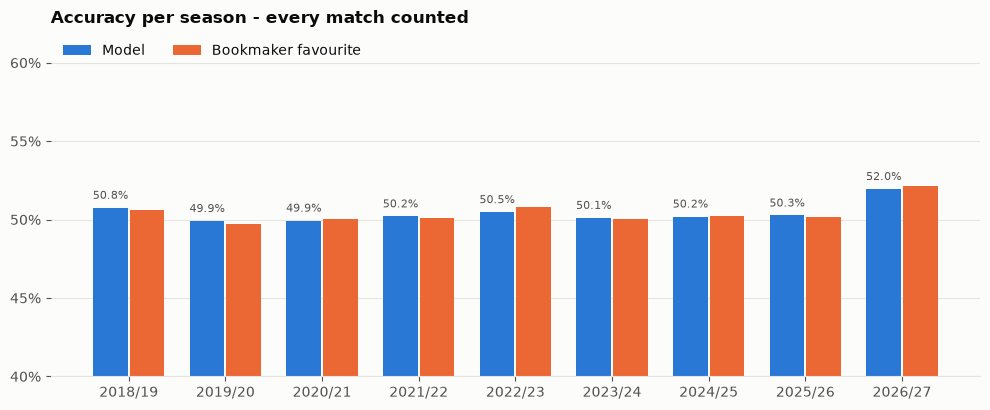

In [22]:
bs = evaluate.by_group(bt, "fold", S["confident_threshold"], S["strong_threshold"])
charts.season_accuracy(bs);
show(bs[["fold","matches","accuracy","accuracy_bookie","logloss","logloss_bookie","conf_acc","conf_share","strong_acc","strong_share"]])

### Confidence: the more sure the model is, the more often it is right

At least this sure,Share of matches,Matches,Model
35.0%,98.1%,"98,759",50.6%
40.0%,78.7%,"79,215",54.0%
45.0%,59.0%,"59,463",57.7%
50.0%,42.6%,"42,919",62.0%
55.0%,30.8%,"31,058",65.7%
60.0%,20.4%,"20,514",70.1%
65.0%,13.6%,"13,740",73.8%
70.0%,9.0%,"9,025",77.2%
75.0%,5.2%,"5,228",80.9%
80.0%,2.6%,"2,603",85.2%


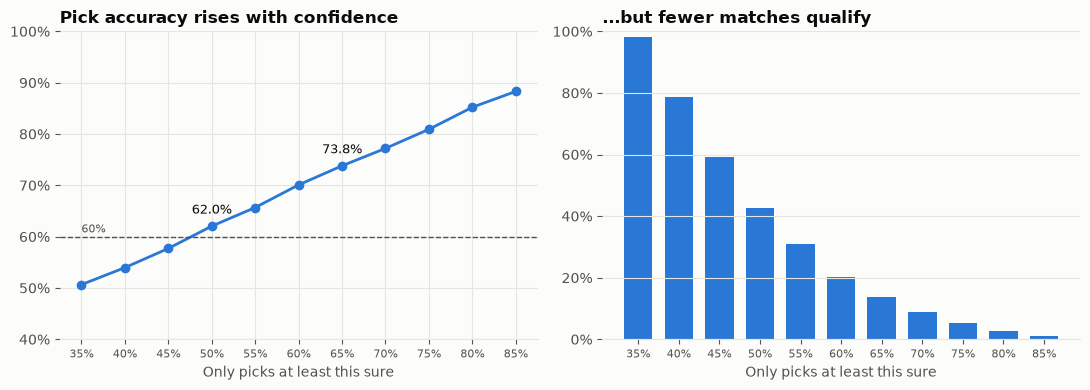

In [23]:
curve = evaluate.threshold_curve(bt)
charts.confidence(curve, S["confident_threshold"], S["strong_threshold"]);
show(curve)

### Calibration
When the model says 60%, does it happen about 60% of the time? Dots on the line = honest probabilities.

Range,Model said,Really happened,Outcomes
0%-10%,7.3%,7.0%,"7,517"
10%-20%,16.1%,16.3%,"37,853"
20%-30%,25.8%,25.9%,"111,089"
30%-40%,34.0%,33.9%,"66,472"
40%-50%,44.7%,44.4%,"36,298"
50%-60%,54.7%,54.7%,"22,405"
60%-70%,64.4%,64.5%,"11,489"
70%-80%,74.4%,73.9%,"6,422"
80%-90%,84.0%,84.9%,"2,535"
90%-100%,90.6%,97.1%,68


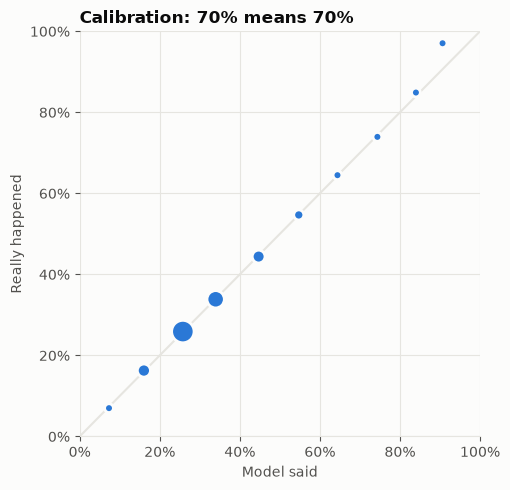

In [24]:
cal = evaluate.calibration(bt)
charts.calibration(cal);
show(cal)

### By league
Some leagues are easier to predict than others. Use this to choose where to play.

Code,League,Matches,Model,Bookmaker,Picks 50%+,Share 50%+,Picks 65%+,Number 65%+
P1,Portugal - Primeira Liga,"2,538",55.9%,56.3%,71.5%,48.7%,80.1%,753
G1,Greece - Super League,"1,969",53.9%,53.4%,69.0%,54.0%,78.0%,600
CHN,China - Super League,"1,986",56.7%,56.6%,68.4%,58.4%,79.1%,560
SC0,Scotland - Premiership,"1,844",55.2%,55.1%,68.1%,51.9%,76.8%,514
T1,Turkey - Super Lig,"2,843",52.7%,52.6%,65.1%,43.4%,74.2%,449
I1,Italy - Serie A,"3,139",54.6%,54.6%,64.8%,56.0%,72.3%,783
N1,Netherlands - Eredivisie,"2,473",56.0%,56.1%,64.7%,60.4%,74.4%,773
E0,England - Premier League,"3,130",54.4%,54.8%,64.5%,57.3%,74.4%,856
SWE,Sweden - Allsvenskan,"2,058",52.5%,52.3%,64.2%,50.3%,76.9%,376
SP1,Spain - La Liga,"3,149",53.2%,53.2%,64.2%,48.9%,75.7%,610


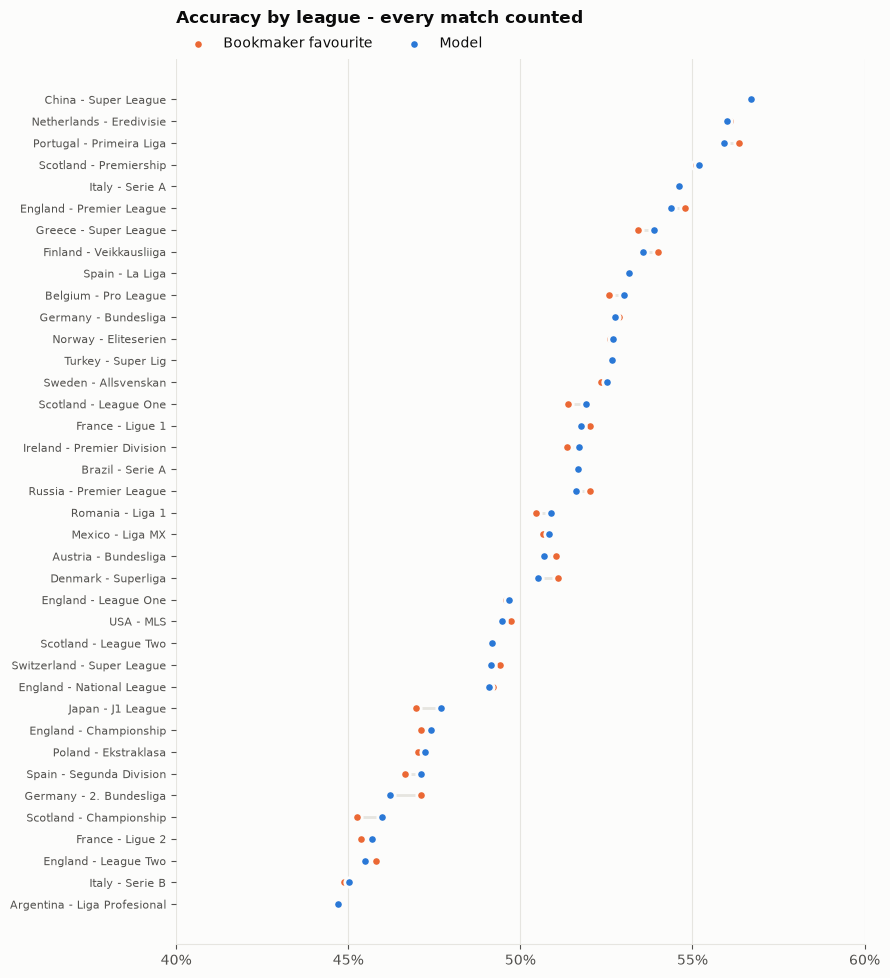

In [25]:
bl = evaluate.by_group(bt, "league", S["confident_threshold"], S["strong_threshold"])
charts.league_accuracy(bl, league_label);
bl.insert(1, "name", bl["league"].map(league_label))
show(bl.sort_values("conf_acc", ascending=False)[["league","name","matches","accuracy","accuracy_bookie","conf_acc","conf_share","strong_acc","strong_n"]])

### Is the model better than the bookmaker? (significance test)

Paired bootstrap on log-loss (2,000 resamples of match days) and a sign test on accuracy.
`p_value` below 0.05 would mean a statistically significant edge.

In [26]:
sig = evaluate.significance(bt)
print(f"Log-loss gain vs bookmaker: {sig['logloss_gain']:+.4f} (95% range {sig['ci_low']:+.4f} to {sig['ci_high']:+.4f}), p = {sig['p_value']:.3f}")
print(f"Matches only the model got right: {sig['acc_only_model']:,} | only the bookmaker: {sig['acc_only_bookie']:,} | p = {sig['acc_p_value']:.3f}")
if sig["p_value"] < 0.05:
    print("-> The model's probabilities are measurably better than the bookmaker's, but the gain is very small.")
    print("   It is not enough on its own to beat the bookmaker's margin of about 6-7%. Parts 6 and 7 show the real profit.")
else:
    print("-> No significant difference from the bookmaker's probabilities on all matches.")

Log-loss gain vs bookmaker: +0.0005 (95% range +0.0001 to +0.0009), p = 0.006
Matches only the model got right: 1,297 | only the bookmaker: 1,283 | p = 0.399
-> The model's probabilities are measurably better than the bookmaker's, but the gain is very small.
   It is not enough on its own to beat the bookmaker's margin of about 6-7%. Parts 6 and 7 show the real profit.


## 5. Goals, corners, cards and shots

In [27]:
g = evaluate.goals_summary(bt)
rows = [["Over/Under 2.5", g["ou_acc"], g["ou_base"], g["ou_strong_acc"], g["ou_strong_n"]],
        ["Both teams to score", g["btts_acc"], g["btts_base"], g["btts_strong_acc"], g["btts_strong_n"]]]
show(pd.DataFrame(rows, columns=["Market", "Accuracy", "Always pick the most common", "65%+ picks accuracy", "65%+ picks"]))
if "ou_acc_bookie" in g:
    print(f"O/U 2.5 where bookmaker odds exist ({g['ou_mk_matches']:,} matches): model {g['ou_acc_on_mk']:.1%} vs bookmaker {g['ou_acc_bookie']:.1%}, "
          f"log-loss {g['ou_ll_on_mk']:.4f} vs {g['ou_ll_bookie']:.4f}")

Market,Accuracy,Always pick the most common,65%+ picks accuracy,65%+ picks
Over/Under 2.5,57.3%,50.5%,67.4%,"8,925"
Both teams to score,54.8%,52.7%,65.5%,"1,246"


O/U 2.5 where bookmaker odds exist (63,175 matches): model 57.0% vs bookmaker 57.0%, log-loss 0.6781 vs 0.6769


### More bets: over 1.5, teams to score, corners, cards, shots

Same walk-forward test, 22 main leagues. **This tests accuracy only.** Old odds for these bets are not in the free data, so their profit can't be tested.

How to read it:
- **Model said / Happened**: on average, did the model's chance match what really happened? Close = honest chances.
- **Right**: when the model was 60%+ sure of one side, how often it was right. **Model said (60%+)** is the chance it gave those picks.
- **Always likelier side**: what you get with no model at all, always picking the more common side. If *Right* is much higher on a line where the two sides are about equal, the model is really adding something. On lopsided lines, like over 1.5, a high *Right* mostly comes from the line itself, and the odds are low for the same reason.

Live, these bets use the half model, half market chance when real odds exist, because the bookmaker prices them too.

In [28]:
bp = pipeline.load_more_bets()
bp = bp[bp["league"].isin(LEAGUE_FILTER or MAIN_LEAGUES)] if bp is not None else None
if bp is not None and len(bp):
    show(props.accuracy_table(bp))
    print("Corner 1X2: chance only in the Excel file, usually no odds in the free API")
    show(props.corner_1x2_table(bp))

Bet,Matches,Happened,Model said,60%+ picks,Share,Right,Model said (60%+),Always likelier side,Lowest season
Over 1.5,"63,258",74.9%,75.1%,"62,557",98.9%,75.0%,75.3%,74.9%,73.3%
Over 3.5,"63,258",28.3%,28.5%,"56,779",89.8%,73.5%,73.7%,71.7%,69.0%
Home team to score,"63,258",76.4%,76.4%,"60,166",95.1%,77.5%,77.4%,76.4%,75.1%
Away team to score,"63,258",68.8%,68.9%,"51,425",81.3%,72.0%,72.2%,68.8%,71.2%
Home wins by 2+,"63,258",21.5%,21.5%,"58,290",92.1%,81.3%,81.5%,78.5%,78.6%
Away wins by 2+,"63,258",13.5%,13.5%,"61,488",97.2%,87.5%,87.5%,86.5%,86.5%
Favourite or over 2.5,"63,177",70.2%,70.1%,"55,707",88.2%,71.8%,72.0%,70.2%,70.9%
Corners over 8.5,"58,996",62.9%,64.3%,"45,533",77.2%,65.7%,66.8%,62.9%,63.6%
Corners over 9.5,"58,996",51.1%,52.4%,"9,543",16.2%,60.8%,62.5%,51.1%,59.3%
Corners over 10.5,"58,996",39.5%,40.8%,"26,179",44.4%,66.1%,65.0%,60.5%,63.9%


Corner 1X2: chance only in the Excel file, usually no odds in the free API


Result,Model said,Happened
More home corners,53.8%,53.3%
Level,10.3%,9.5%
More away corners,35.9%,37.2%


## 5b. National teams: the test

National teams have their own model: Elo ratings for every country (a win against a strong team counts more, World Cup matches count
more than friendlies, the home team gets a bonus) plus recent goals, then logistic regression + LightGBM for home/draw/away and Poisson for goals.
Data: every international result since 1872 (free, updated after each window), saved in `data_snapshot/intl_results.csv.gz`.

**Same walk-forward test:** each year is predicted by a model trained only on the years before it. About 30 seconds, so set `RUN_INTL_BACKTEST = True` to run it yourself.
- **Higher rated wins** = always pick the team with the higher rating. The model gets about the same on all matches: its value is in knowing **how sure** to be.
- No old odds exist for national teams in the free data, so **accuracy is tested, profit is not**. Their odds are usually low, because the bookmakers know the favourites too.

In [29]:
RUN_INTL_BACKTEST = False
ibt = intl.load_backtest()
if ibt is None or RUN_INTL_BACKTEST:
    ibt = intl.backtest(use_snapshot=USE_SNAPSHOT)
print(f"{len(ibt):,} national team matches tested, years {ibt['fold'].min()} to {ibt['fold'].max()}")
show(intl.accuracy_table(ibt))

10,185 national team matches tested, years 2016 to 2026


Group,Matches,Accuracy,Higher rated wins,Picks 50%+,Share 50%+,Picks 65%+,Share 65%+,Picks 75%+,Share 75%+,Log-loss
All,"10,185",60.2%,60.1%,69.1%,66.0%,78.5%,38.6%,85.0%,23.4%,0.8696
Competitive (no friendlies),"7,324",61.9%,61.5%,70.1%,68.9%,79.4%,42.0%,85.7%,26.5%,0.8458
Friendlies,"2,861",56.1%,56.4%,66.0%,58.5%,75.3%,30.1%,81.9%,15.2%,0.9306
World Cup,232,57.8%,59.5%,67.7%,56.0%,72.7%,23.7%,65.0%,8.6%,0.9516
World Cup qualifiers,"2,338",64.9%,64.6%,73.1%,72.9%,82.1%,48.6%,87.8%,34.3%,0.7836
Euro,153,50.3%,51.6%,54.7%,62.1%,68.3%,26.8%,,8.5%,1.0086
Euro qualifiers,501,70.5%,71.3%,77.7%,78.0%,85.9%,57.9%,90.0%,44.1%,0.6918
UEFA Nations League,762,55.1%,55.0%,63.2%,58.1%,75.2%,27.0%,81.4%,12.7%,0.9595
Africa Cup of Nations,240,52.5%,52.1%,59.6%,58.8%,60.9%,28.7%,80.0%,12.5%,0.9746
AFCON qualifiers,745,58.9%,57.4%,65.6%,72.6%,71.9%,45.4%,76.5%,26.3%,0.9031


### Competitive matches, year by year

In [30]:
show(intl.season_table(ibt))

Year,Matches,Accuracy,Picks 50%+,Picks 65%+,65%+ picks
2016,594,63.8%,70.0%,81.6%,239
2017,588,59.0%,68.1%,79.2%,226
2018,468,59.8%,71.7%,81.1%,169
2019,866,65.0%,73.4%,83.3%,412
2020,252,54.4%,61.0%,76.6%,77
2021,900,65.8%,74.3%,82.8%,418
2022,616,57.3%,64.7%,73.7%,232
2023,765,63.8%,71.1%,79.2%,360
2024,990,58.5%,66.2%,74.4%,414
2025,760,64.1%,72.6%,81.0%,347


### Calibration: when the model says 70%, does it happen about 70% of the time? (competitive matches)

In [31]:
show(intl.calibration_table(ibt))

Range,Matches,Model said,Really happened
40%-50%,"1,628",45.1%,45.3%
50%-60%,"1,325",54.9%,52.2%
60%-65%,649,62.5%,62.6%
65%-70%,607,67.5%,66.2%
70%-75%,524,72.5%,71.2%
75%-80%,555,77.4%,75.5%
80%-90%,871,84.8%,86.6%
90%-100%,518,93.8%,95.2%


### Goals: over/under, BTTS

In [32]:
show(intl.goals_table(ibt))

Bet,Happened,Model said,Right,Always likelier side,Model said (60%+),Share 60%+
Over 2.5,49.1%,49.9%,58.6%,50.9%,65.2%,34.3%
Over 1.5,72.3%,73.7%,72.3%,72.3%,72.4%,99.2%
Under 3.5,71.3%,71.0%,72.7%,71.3%,74.8%,89.6%
BTTS yes,42.7%,43.7%,57.4%,57.3%,66.1%,25.7%


## 5c. Bangers by market and the mixed acca: the test

The Bangers tab, tested with **exactly the live code** on the walk-forward backtest (each season predicted only with the seasons before it).
1X2 and goals: 38 leagues. Corners, cards and shots: the 22 main leagues. National teams: competitive matches only.
- **Right**: how often the pick won. **Model said**: the average chance it gave. Close = honest chances.
- **Lowest season**: the worst single season. Bangers are not sure things: about 1 in 5 still loses.
- The accas: **Won** = all legs won. Profit only for 1X2, at real old average odds. For the others no old odds exist, so the price is an estimate and profit is not tested.
- The mixed acca: one a day, top 2 (and top 1) of each kind. **Only 1 leg lost** = the days where a single leg spoiled the slip. Most of its prices are estimates, so profit is not tested.

In [33]:
bt_all, more_all = pipeline.load_backtest(), pipeline.load_more_bets()
if bt_all is not None:
    show(bangers.accuracy_table(bt_all, more_all, S, intl.load_backtest()))
    show(bangers.acca_table(bt_all, more_all, S))
    show(bangers.mixed_table(bt_all, more_all, S))

Bangers,Picks,Share of matches,Per season,Right,Model said,Lowest season
1X2,"5,239",5.2%,582,81.0%,80.7%,78.1%
Over 2.5 goals,518,0.5%,58,80.7%,78.2%,72.7%
Over 1.5 goals,"31,137",49.2%,"3,460",79.8%,80.6%,79.1%
Corners over,"58,232",92.1%,"6,470",78.6%,79.8%,75.5%
Cards over,"30,819",48.7%,"3,424",81.5%,80.7%,79.1%
Shots over,"56,480",89.3%,"6,276",78.4%,77.9%,75.9%
National teams: 1X2,"1,640",27.2%,149,85.7%,85.2%,76.8%
National teams: Over 1.5 goals,"2,233",37.1%,203,81.3%,82.4%,71.7%


Acca,Slips,Legs (avg),Odds (avg),Model said,Won,Profit per slip,Real odds slips
1X2 acca,514,3.5,2.22,45.2%,41.8%,-7.7%,514
Over 2.5 goals acca,9,3.3,2.18,42.9%,44.4%,,9
Over 1.5 goals acca,"1,164",4.0,2.25,33.9%,33.2%,,0
Corners over acca,"1,580",4.0,2.27,33.6%,30.1%,,0
Cards over acca,"1,167",4.0,2.26,33.8%,36.8%,,0
Shots over acca,"1,774",4.0,2.30,33.2%,35.9%,,0


Mixed acca,Slips,Legs (avg),Odds (avg),Model said,Won,Only 1 leg lost,Legs right
top 1 of each kind,"2,028",4.4,2.07,39.2%,37.7%,41.5%,80.0%
top 2 of each kind,"2,075",7.6,3.76,22.3%,21.9%,32.1%,79.5%


## 5d. Cups: the test

Cups have their own model, built on the clubs' **league** form (Elo, recent points and goals, attack and defence, all from before kickoff):
- **domestic cups**: clubs from different levels meet. A club below our leagues is a *small club*: the model only knows it plays lower.
- **European cups**: each country gets a strength, learned from the European results (England stronger than Greece, and so on).
- finals (and FA Cup semi-finals) are on neutral ground. Trained on the **90 minute score**, because bets settle after 90 minutes.
- model: logistic regression with strong regularisation (it beat LR + LightGBM here: the cup data is small). Poisson for goals.

Data: API-Football, seasons 2022/23 to 2024/25 (what the free plan has), saved in `data_snapshot/cup_results.csv.gz`, plus the newest results from the daily fixture lists.
**Same walk-forward test:** 2023/24 predicted with a model trained only on 2022/23, 2024/25 with 2022/23 + 2023/24.
Skipped, no blind guesses: European matches with a club from a country we have no league for, and small clubs whose name looks like a league club's.
**Stronger club wins** = always pick the club with the higher rating. Accuracy is tested, profit is not: no old cup odds in the free data.

In [34]:
RUN_CUP_BACKTEST = False      # True: run it again (about 2 minutes)
cbt = cups.load_backtest()
if cbt is None or RUN_CUP_BACKTEST:
    cbt = cups.backtest(pd.read_csv(pipeline.SNAPSHOT, parse_dates=["date"], dtype={"time": str, "season": str}).fillna({"time": "", "season": ""}))
print(f"{len(cbt):,} cup matches tested, seasons {cbt['fold'].min()} and {cbt['fold'].max()}")
show(cups.accuracy_table(cbt))

2,134 cup matches tested, seasons 2023/24 and 2024/25


Group,Matches,Accuracy,Stronger club wins,Picks 50%+,Share 50%+,Picks 65%+,Share 65%+,Picks 75%+,75%+ picks,Log-loss
All cups,"2,134",56.9%,55.3%,63.5%,69.0%,75.4%,30.1%,79.2%,259,0.9434
European cups,740,51.6%,50.8%,58.3%,59.6%,68.9%,21.8%,71.2%,66,1.0035
Domestic cups,"1,394",59.8%,57.7%,65.8%,74.0%,77.6%,34.6%,81.9%,193,0.9115
"Domestic, both clubs in our leagues",910,55.6%,55.5%,64.2%,63.8%,78.7%,24.3%,87.7%,65,0.9501
"Domestic, against a small club",484,67.6%,61.8%,67.8%,93.2%,76.6%,53.9%,78.9%,128,0.8390


### Season by season, and by cup

In [35]:
show(cups.season_table(cbt))
show(cups.competition_table(cbt))

Season,Matches,Accuracy,Picks 65%+,Picks 75%+,75%+ picks
2023/24,"1,023",57.1%,74.8%,79.3%,116
2024/25,"1,111",56.8%,75.9%,79.0%,143


Cup,Matches,Accuracy,Picks 65%+,65%+ picks
Champions League,295,54.9%,78.0%,59
FA Cup,293,54.6%,72.7%,88
Europa League,248,50.4%,60.0%,50
Conference League,197,48.2%,67.3%,52
League Cup (Carabao),186,54.3%,70.3%,37
Scottish League Cup,174,65.5%,86.8%,68
Copa del Rey,174,66.7%,79.2%,77
Coupe de France,145,63.4%,73.1%,52
DFB Pokal,110,61.8%,71.7%,53
Scottish Cup,102,61.8%,82.9%,41


### Calibration: when the model says 70%, does it happen about 70% of the time?

In [36]:
show(cups.calibration_table(cbt))

Range,Matches,Model said,Really happened
40%-50%,539,45.2%,43.6%
50%-60%,579,55.0%,51.5%
60%-65%,251,62.5%,61.0%
65%-70%,212,67.4%,68.9%
70%-75%,172,72.4%,77.9%
75%-80%,124,77.3%,71.8%
80%-90%,124,83.8%,86.3%
90%-100%,11,92.1%,81.8%


### Goals: over/under, BTTS

In [37]:
show(cups.goals_table(cbt))

Bet,Happened,Model said,Right,Always likelier side,Model said (60%+),Share 60%+
Over 2.5,59.3%,57.9%,57.9%,59.3%,66.1%,37.1%
Over 1.5,80.6%,79.8%,80.6%,80.6%,80.6%,100.0%
Under 3.5,62.2%,63.7%,63.8%,62.2%,65.5%,75.7%
BTTS yes,53.8%,52.5%,53.4%,53.8%,55.7%,13.5%


## 6. Value bets and profit

Flat 1-unit stakes at **average** bookmaker odds (what you can really get), every test season.

In [38]:
scan = evaluate.edge_scan(bt, S)
show(scan)
r, vb = evaluate.value_backtest(bt, S)
if r["bets"]:
    lo, hi = evaluate.roi_range(vb["profit"], bt.loc[vb.index, "date"])
    print(f"Default rule (edge {S['value_min_edge']:.0%}+): {r['bets']:,} bets, ROI {r['roi']:+.1%}, 95% range {lo:+.1%} to {hi:+.1%}. "
          + ("Proven profit." if lo > 0 else "The range includes zero, so this is not a proven profit."))
rows = [{"Bet on": f"every pick {t:.0%}+", **evaluate.pick_roi(bt, t)} for t in (0.5, 0.6, 0.65, 0.7, 0.75)]
show(pd.DataFrame(rows))

Min edge,Bets,Hit rate,Avg odds,ROI
0.0%,"25,435",43.3%,2.55,-2.0%
2.0%,"10,838",40.3%,2.69,-2.5%
5.0%,"2,658",36.3%,2.88,-1.9%
8.0%,694,34.4%,2.97,-3.3%
10.0%,303,35.3%,3.03,2.7%
15.0%,77,33.8%,3.23,2.0%
20.0%,36,36.1%,3.36,16.0%


Default rule (edge 5%+): 2,658 bets, ROI -1.9%, 95% range -7.0% to +3.4%. The range includes zero, so this is not a proven profit.


Bet on,Bets,Hit rate,Avg odds,ROI
every pick 50%+,"42,919",62.0%,1.61,-2.4%
every pick 60%+,"20,514",70.1%,1.42,-1.7%
every pick 65%+,"13,740",73.8%,1.35,-1.5%
every pick 70%+,"9,025",77.2%,1.29,-1.4%
every pick 75%+,"5,228",80.9%,1.22,-1.4%


## 7. The accas - tested on the past

Every match day in the backtest, the slips are built exactly like the live system builds them, then settled.
Break-even = 1 / average odds. Which leagues go into slips is set by `acca_leagues` in `settings.json`.

**The main acca is mixed, not only favourites to win:** win, double chance and over/under 2.5. A slip has at most 2 of one type, and a match is used only once.
For over/under the chance is half the model and half the market, because the market is a little better than the model there.

Limits of this test:
- **Double chance prices are worked out from the win odds**, because old double chance odds are not in the free data. Real prices can differ a little. Live, real odds are used when API-Football has them.
- **The other acca is not in this test.** Its old odds are not in the free data, so its profit can't be tested. Its accuracy is in part 5 and below. Your bet tracker logs each acca apart, so it will show how they really do over time.

6,860 slips on 1,861 match days | won 1,093 = 15.9% (break-even 17.7%) | avg odds 5.64, 3.6 legs | ROI -11.6%
Days with all 5 slips: 981 -> at least 1 slip won on 59%, at least 2 on 19%, all 5 on 0.0%


Season,Slips,Hit rate,Avg odds,ROI,Break-even
2018/19,820,18.2%,5.63,-0.1%,17.7%
2019/20,715,14.4%,5.62,-19.9%,17.8%
2020/21,967,15.4%,5.67,-14.5%,17.6%
2021/22,865,17.7%,5.65,-0.9%,17.7%
2022/23,835,16.2%,5.66,-9.1%,17.7%
2023/24,786,16.5%,5.60,-9.8%,17.9%
2024/25,811,15.2%,5.62,-16.9%,17.8%
2025/26,820,12.7%,5.61,-29.7%,17.8%
2026/27,241,19.5%,5.68,13.1%,17.6%


Which bets went into the slips, and did they happen as often as the model said?


Bet,Legs,Model said,Really happened,Avg odds
Home win,6063,63.9%,62.9%,1.59
Draw or away,4717,64.5%,62.4%,1.54
Over 2.5,4432,58.5%,56.9%,1.70
Under 2.5,4241,56.5%,55.5%,1.73
Away win,3670,61.0%,59.4%,1.69
Home or draw,1489,71.4%,68.8%,1.40
Draw,1,52.6%,100.0%,2.09


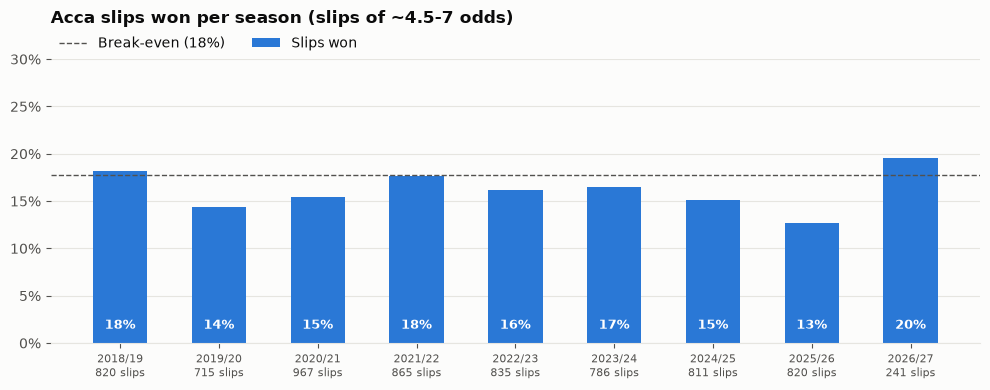

In [39]:
acc, slips_bt, days_bt = evaluate.acca_backtest(bt, S)
print(f"{acc['slips']:,} slips on {acc['days']:,} match days | won {acc['won']:,} = {acc['hit']:.1%} "
      f"(break-even {acc['break_even']:.1%}) | avg odds {acc['avg_odds']:.2f}, {acc['avg_legs']:.1f} legs | ROI {acc['roi']:+.1%}")
print(f"Days with all {S['acca_slips']} slips: {acc['full_days']:,} -> at least 1 slip won on {acc['days_1plus']:.0%}, "
      f"at least 2 on {acc['days_2plus']:.0%}, all 5 on {acc['days_5']:.1%}")
slips_bt["fold"] = slips_bt["date"].apply(lambda d: f"{d.year if d.month >= 7 else d.year - 1}/{(d.year + 1 if d.month >= 7 else d.year) % 100:02d}")
per = slips_bt.groupby("fold").agg(slips=("won", "size"), hit=("won", "mean"), avg_odds=("odds", "mean"), roi=("profit", "mean")).reset_index()
per["break_even"] = 1 / per["avg_odds"]
charts.acca_by_season(per);
show(per)
print("Which bets went into the slips, and did they happen as often as the model said?")
show(acc["types"])

### BTTS accuracy
No profit test here, because old BTTS odds don't exist. Only: when the model says it, does it happen? (22 main leagues)

In [40]:
m = bt[bt["league"].isin(MAIN_LEAGUES)]
rows = []
for th in (0.55, 0.60, 0.65):
    y, n = m[m["p_btts"] >= th], m[m["p_btts"] <= 1 - th]
    rows.append({"Model chance": f"{th:.0%}+", "BTTS yes: matches": len(y), "Model said": y["p_btts"].mean(), "Happened": y["btts"].mean(),
                 "BTTS no: matches": len(n), "Model said (no)": 1 - n["p_btts"].mean(), "Happened (no)": 1 - n["btts"].mean()})
display(pd.DataFrame(rows).style.format({"Model said": "{:.1%}", "Happened": "{:.1%}", "Model said (no)": "{:.1%}", "Happened (no)": "{:.1%}", "BTTS yes: matches": "{:,}", "BTTS no: matches": "{:,}"}).hide(axis="index"))

Model chance,BTTS yes: matches,Model said,Happened,BTTS no: matches,Model said (no),Happened (no)
55%+,"20,527",58.8%,58.4%,"5,004",57.6%,57.1%
60%+,"5,917",62.8%,62.0%,690,62.5%,63.0%
65%+,"1,076",66.4%,65.7%,92,66.4%,62.0%


### Which combination makes a profit?

Every combination of the bet types with old odds, at five leg strengths, best first. **Three made a small profit at average odds, all favourites to win only:
every leg 70%+ (the banger acca), 65%+ (the strong acca) and 60%+. For all three the range still includes a loss, so none is proven.** All the others lost.
More bets gave more slips, not more profit. Stronger favourites did better.

Set `RUN_COMBINATIONS = True` to run this again (a few minutes).

In [41]:
RUN_COMBINATIONS = False
COMBO_FILE = pipeline.OUTPUT / "combination_test.csv"
if RUN_COMBINATIONS or not COMBO_FILE.exists():
    evaluate.combination_test(pipeline.load_backtest(), S).to_csv(COMBO_FILE, index=False)
show(pd.read_csv(COMBO_FILE))

Bets,Legs from,Slips,Slips a day,Hit rate,ROI,95% range,Bet365,Best odds,2018-21,2022 on,Seasons with profit
Win,70%,378,1.1,21.2%,7.2%,-13.3% to +29.0%,8.6%,21.0%,16.6%,0.9%,6 of 9
Win,65%,899,1.5,19.9%,4.9%,-8.8% to +19.1%,2.3%,9.0%,6.3%,3.7%,6 of 9
Win,60%,"1,838",2.2,18.9%,0.8%,-9.0% to +11.0%,-4.2%,13.4%,5.9%,-3.5%,4 of 9
Win + Over/under,60%,"1,532",1.9,18.8%,-1.7%,-11.4% to +8.5%,-6.9%,1.4%,0.8%,-4.0%,4 of 9
Over/under,65%,595,1.2,18.2%,-3.7%,-20.2% to +12.4%,3.4%,14.9%,-12.7%,3.3%,5 of 9
Win + Double chance,50%,"3,540",2.7,17.7%,-4.5%,-11.0% to +2.2%,-6.5%,6.8%,-5.3%,-3.6%,4 of 9
Win,55%,"3,193",2.7,17.3%,-4.7%,-12.7% to +3.1%,-2.9%,6.4%,-3.9%,-5.3%,3 of 9
Win + Double chance,55%,"1,978",2.1,17.7%,-6.1%,-14.7% to +2.7%,-3.9%,5.5%,-4.2%,-8.2%,4 of 9
Win + Over/under,50%,"5,472",3.2,16.6%,-7.5%,-12.9% to -2.0%,-11.0%,0.1%,-2.9%,-11.9%,2 of 9
Win,50%,"4,339",3.0,16.6%,-8.3%,-14.4% to -2.2%,-9.4%,5.9%,-7.3%,-9.1%,2 of 9


### Strong and banger accas: how much can you trust them?

Favourites only, at different leg strengths and total odds. Legs of 75%+ almost never reach 5 odds, which is why the banger acca uses 70%+.

**No acca has proven profit. Treat the strong and banger accas as a small profit or about break-even, nothing more.** Reasons, all measured:
- **Acca numbers are very sensitive.** Running this same test, with the same model and data, on other library versions gave the banger acca **+27.6%** instead of **+7.2%**, and the strong acca +5.9% instead of +4.9%. A tiny change swaps a few legs, and a few slips flip between winning and losing.
- **The range includes a loss** for both, and they are not statistically significant (below).
- **They are the best of many combinations**, which makes them look better than they are.
- A few wins make a big part of the profit, there are only about 40 banger slips a season, and some seasons lose.

The picks are much steadier than the accas: the same change moved picks 50%+ by 0.1 points and picks 65%+ by less than 0.1. Your bet tracker logs each acca apart, so use small stakes and let your own record decide.

In [42]:
show(evaluate.favourite_acca_test(bt, S))
from scipy.stats import binomtest
b_acc, b_sl, _ = evaluate.acca_backtest(bt, {**S, "acca_markets": ["win"], "acca_leg_min_prob": S["banger_slips_min_prob"]})
if b_acc["slips"]:
    n_tried = len(pd.read_csv(COMBO_FILE))
    p = binomtest(b_acc["won"], b_acc["slips"], b_acc["break_even"], alternative="greater").pvalue
    top = b_sl.sort_values("profit", ascending=False).head(10)["profit"].sum() / b_sl["profit"].sum()
    print(f"Banger acca: won {b_acc['won']} of {b_acc['slips']} = {b_acc['hit']:.1%} | the model expected {b_acc['expected_hit']:.1%} | break-even {b_acc['break_even']:.1%}")
    print(f"Chance of this result if it really were only break-even: p = {p:.3f}. After allowing for {n_tried} combinations tried: p = {min(1, p * n_tried):.2f} (below 0.05 would be significant)")
    print(f"The 10 biggest wins make {top:.0%} of its profit" + (" (over 100% = without them it would lose)" if top > 1 else ""))
    b_sl["fold"] = b_sl["date"].apply(lambda d: f"{d.year if d.month >= 7 else d.year - 1}/{(d.year + 1 if d.month >= 7 else d.year) % 100:02d}")
    show(b_sl.groupby("fold").agg(slips=("won", "size"), hit=("won", "mean"), avg_odds=("odds", "mean"), roi=("profit", "mean")).reset_index())

Legs from,Total odds,Slips,Legs,Avg odds,Hit rate,Break-even,ROI,95% range,Bet365,Best odds,2018-21,2022 on,Seasons with profit
65%,4.5-7,899,5.3,5.27,19.9%,19.0%,4.9%,-8.8% to +19.1%,2.3%,9.0%,6.3%,3.7%,6 of 9
65%,3-4.5,"1,388",4.0,3.53,26.9%,28.4%,-5.6%,-14.6% to +3.3%,-1.7%,3.4%,0.7%,-10.8%,4 of 9
65%,2-3,"2,321",2.7,2.34,42.4%,42.8%,-1.8%,-7.0% to +3.2%,-2.2%,5.0%,1.3%,-4.5%,4 of 9
70%,4.5-7,378,5.9,5.14,21.2%,19.5%,7.2%,-13.3% to +29.0%,8.6%,21.0%,16.6%,0.9%,6 of 9
70%,3-4.5,641,4.5,3.43,30.1%,29.2%,1.9%,-9.8% to +14.6%,4.7%,9.8%,2.8%,1.2%,5 of 9
70%,2-3,"1,186",3.1,2.32,43.5%,43.2%,-0.2%,-6.5% to +6.5%,0.4%,8.4%,-3.8%,2.5%,5 of 9
75%,4.5-7,49,6.7,4.96,14.3%,20.1%,-28.9%,-78.6% to +21.7%,-37.6%,-3.5%,-49.6%,-14.6%,2 of 8
75%,3-4.5,162,5.2,3.34,27.2%,29.9%,-9.8%,-32.1% to +13.5%,-14.4%,14.6%,-5.9%,-12.6%,1 of 9
75%,2-3,434,3.5,2.21,43.8%,45.2%,-3.2%,-13.7% to +7.1%,-2.2%,7.9%,-7.4%,-0.4%,4 of 9


Banger acca: won 80 of 378 = 21.2% | the model expected 20.0% | break-even 19.5%
Chance of this result if it really were only break-even: p = 0.218. After allowing for 28 combinations tried: p = 1.00 (below 0.05 would be significant)
The 10 biggest wins make 180% of its profit (over 100% = without them it would lose)


Season,Slips,Hit rate,Avg odds,ROI
2018/19,35,31.4%,5.12,58.4%
2019/20,54,11.1%,5.15,-42.2%
2020/21,36,30.6%,5.06,52.3%
2021/22,27,25.9%,5.15,32.3%
2022/23,52,17.3%,5.12,-13.3%
2023/24,75,14.7%,5.27,-23.1%
2024/25,60,23.3%,5.07,15.2%
2025/26,30,23.3%,5.15,24.1%
2026/27,9,44.4%,4.88,109.8%


### My picks: the exact rule, tested

Each day, only when the model has them: 1 long acca (banger, else strong) and up to 2 safer accas at about 2.3 odds, with no match used twice. Built exactly like the live tab, at the same stake on every slip.

**This is about break-even, not a sure profit.** It is here because it is the most disciplined way to use the model, not because it wins. I chose it after seeing the tests above, so the real result can be worse. The reasons not to trust acca numbers, above, apply here too.

In [43]:
mp = evaluate.my_picks_test(pipeline.load_backtest(), S)
show(mp["table"])
print(f"Played on {mp['days']:,} of {mp['all_days']:,} match days. Worst losing runs: {mp['run_long']} long slips in a row, {mp['run_safer']} safer slips in a row.")

Set,Slips,Legs,Avg odds,Hit rate,Break-even,ROI,95% range,Bet365
Long acca: banger,340,5.9,5.14,21.5%,19.4%,8.9%,-12.6% to +32.1%,11.2%
Long acca: strong,270,5.1,5.26,18.9%,19.0%,0.5%,-23.9% to +25.4%,-2.0%
Safer acca,339,3.2,2.29,41.9%,43.7%,-4.6%,-17.1% to +7.9%,-10.7%
All my picks,949,4.7,4.16,28.0%,24.1%,1.7%,-9.8% to +13.5%,-0.3%


Played on 738 of 2,210 match days. Worst losing runs: 18 long slips in a row, 10 safer slips in a row.


### The price you take decides the result

The same strategy at three prices: average of all bookmakers, one real bookmaker (Bet365), and the best price on the
whole market. Treat "best price" as the upper limit: it means always having an account at the bookmaker that pays the most.
Compare your own bookmaker's odds with the `Odds` and `Best odds` columns in the Excel file.

In [44]:
rows = []
for name, price in (("Average odds", "avg"), ("Bet365", "bet365"), ("Best on the market", "best")):
    a, _, _ = evaluate.acca_backtest(bt, S, price)
    rows.append({"Price": name, "slips": a["slips"], "hit": a["hit"], "break_even": a["break_even"], "avg_odds": a["avg_odds"], "roi": a["roi"]})
show(pd.DataFrame(rows))

rows = []
MIX = ["win", "double_chance", "over_under"]
base = {**S, "acca_leagues": "main", "acca_leg_min_prob": 0.50, "acca_markets": MIX}
for name, s2 in (("Mixed, legs 50%+ (default)", base),
                 ("Mixed, legs 55%+", {**base, "acca_leg_min_prob": 0.55}),
                 ("Mixed, legs 60%+", {**base, "acca_leg_min_prob": 0.60}),
                 ("Mixed, no double chance", {**base, "acca_markets": ["win", "over_under"]}),
                 ("Mixed, all 38 leagues", {**base, "acca_leagues": "all"}),
                 ("Favourites only, legs 50%+", {**base, "acca_markets": ["win"]}),
                 ("Favourites only, legs 60%+", {**base, "acca_markets": ["win"], "acca_leg_min_prob": 0.60}),
                 ("Strong acca: favourites only, legs 65%+", {**base, "acca_markets": ["win"], "acca_leg_min_prob": 0.65}),
                 ("Banger acca: favourites only, legs 70%+", {**base, "acca_markets": ["win"], "acca_leg_min_prob": 0.70}),
                 ("Strong acca, all 38 leagues", {**base, "acca_markets": ["win"], "acca_leg_min_prob": 0.65, "acca_leagues": "all"})):
    a, sl, dd = evaluate.acca_backtest(bt, s2)
    b, sb, _ = evaluate.acca_backtest(bt, s2, "best")
    wk = pd.to_datetime(dd["date"]).dt.day_of_week >= 5
    lo, hi = evaluate.roi_range(sl["profit"], sl["date"])
    rows.append({"Rule": name, "Slips a day": round(a["slips"] / a["days"], 1), "Weekends with 5 slips": f"{(dd.loc[wk, 'slips'] == 5).mean():.0%}",
                 "hit": a["hit"], "break_even": a["break_even"], "roi": a["roi"], "95% range": f"{lo:+.1%} to {hi:+.1%}", "ROI at best odds": f"{b['roi']:+.1%}"})
show(pd.DataFrame(rows))

Price,Slips,Hit rate,Break-even,Avg odds,ROI
Average odds,"6,860",15.9%,17.7%,5.64,-11.6%
Bet365,"6,631",16.5%,17.6%,5.67,-7.5%
Best on the market,"6,588",18.4%,17.4%,5.76,4.5%


Rule,Slips a day,Weekends with 5 slips,Hit rate,Break-even,ROI,95% range,ROI at best odds
"Mixed, legs 50%+ (default)",3.7,87%,15.9%,17.7%,-11.6%,-16.3% to -6.7%,+4.5%
"Mixed, legs 55%+",3.4,85%,16.1%,17.8%,-11.0%,-16.0% to -5.8%,+10.2%
"Mixed, legs 60%+",3.0,73%,16.0%,18.3%,-13.9%,-19.5% to -8.1%,+5.4%
"Mixed, no double chance",3.2,81%,16.6%,17.6%,-7.5%,-12.9% to -2.0%,+0.1%
"Mixed, all 38 leagues",3.8,85%,16.3%,17.8%,-10.2%,-14.2% to -6.1%,+5.1%
"Favourites only, legs 50%+",3.0,71%,16.6%,17.8%,-8.3%,-14.4% to -2.2%,+5.9%
"Favourites only, legs 60%+",2.2,7%,18.9%,18.4%,0.8%,-9.0% to +11.0%,+13.4%
"Strong acca: favourites only, legs 65%+",1.5,0%,19.9%,19.0%,4.9%,-8.8% to +19.1%,+9.0%
"Banger acca: favourites only, legs 70%+",1.1,0%,21.2%,19.5%,7.2%,-13.3% to +29.0%,+21.0%
"Strong acca, all 38 leagues",1.9,0%,17.0%,18.9%,-11.1%,-21.2% to -0.1%,+5.4%


## 8. Your bet tracker
Every suggestion is logged in `output/bet_tracker.xlsx` and settled automatically. Mark `Played = Y` on the bets you really placed.

In [45]:
show(tracker.summary(tracker.load()))

(nothing to show)


## 9. How it works and why each part was chosen

**Data.** football-data.co.uk is free and has results and bookmaker odds for 38 leagues, 22 seasons for the main leagues. Team names are
cleaned, so a club that changed its name or spelling keeps its history. A saved copy is in `data_snapshot/`.

**Features (what the model reads).** Only information known before kickoff:
Elo strength, form over 5 and 10 matches, home form at home and away form away, goals for and against, shots on target,
attack and defence strength, expected goals, head to head, rest days, league trends and bookmaker odds with the margin removed.

**Why these models:**

| Model | Why it is here |
|---|---|
| Logistic Regression | Simple and stable. The baseline: a fancier model must beat it. |
| XGBoost | Finds patterns that are not straight lines, like form only mattering between close teams. |
| LightGBM | Same family, built differently, so its mistakes are different and mixing the two reduces them. |
| Neural Network | A third way of learning. On this data it is the weakest alone, but the stack decides how much to trust it. |
| Stack (meta model) | Learns on the newest 15% of matches how much to trust each model. This also calibrates: 70% should mean 70%. |

**Tuning.** Optuna tried 30 settings each for XGBoost and LightGBM, on seasons before 2018/19 only, so the backtest never saw them.

**No leak test.** Every future result was scrambled at several dates: no feature before those dates changed.

**Why matches need odds.** The market is the strongest single signal in football. Matches without odds yet use a second model, marked `no odds`, which is weaker.

## 10. Tune the models again (optional, about 20 minutes)

In [46]:
RUN_TUNING = False
if RUN_TUNING:
    from p90 import tuning
    from p90.features import build_features
    from p90.backtest import past_warmup
    res = pipeline.data.load_results(S["leagues"], S["first_season"])
    print(tuning.tune(past_warmup(build_features(res))))
    pipeline.get_models(build_features(res), S, force=True)

## 11. Honest notes

- **Football is random.** Even the bookmakers' favourite wins only about half of all matches. Nobody gets 60% on *every* match.
  The model earns its accuracy by knowing **which** matches are safer: the higher the confidence, the higher the hit rate (part 4).
- **Better probabilities, but no proven profit.** The model's probabilities are measurably better than the bookmaker's, but only by a tiny amount (part 4). The bookmaker's margin is much bigger, so flat betting on picks loses a little, and the value bets and slips are not proven winners (parts 6 and 7).
- **All 38 leagues together sit near 50%.** The bookmaker's favourite gets the same. Top leagues are higher, lower divisions are lower (part 4, by league).
- **Backtest is not a promise.** Past seasons show how the method behaves, not what will happen next week.
- **Odds differ by league in the data.** The 22 main leagues have odds from before the match. The 16 extra leagues only have closing odds in their history, which are harder to beat. Live, all leagues use odds from before the match.
- **Results arrive with a delay.** football-data.co.uk updates about twice a week, so a match played yesterday may not be counted yet in form and Elo, and bets may settle a few days later.
- **The main acca loses at average odds.** Mixing cost a little compared with favourites only (part 7), but gives all 5 slips on more days. Double chance prices in the test are worked out from the win odds.
- **No acca has proven profit.** The strong and banger accas made a small profit in the test, but the range includes a loss, and other library versions moved the banger acca from +7.2% to +27.6% with the same model and data. Do not plan on any acca number.
- **Other leagues do worse in accas.** Strong accas in all 38 leagues lost clearly (part 7), so accas use the 22 main leagues by default. The other leagues' old odds are closing odds, which is a harder test.
- **The other acca: accuracy is tested, profit is not.** Their old odds are not in the free data. More bets mean more slips, not proven profit. An estimated price is not a real price: check it at your bookmaker.
- **National teams: accuracy tested, profit not.** The free data has no old odds for national teams, so their accas can't be tested for profit, and they get no value bets. Friendlies are always WEAK. National team matches only come in the international windows, and only with the API-Football key.
- **1up and 2up are not included.** The free data has no goal minutes, so they can't be predicted or tested.
- **Bet only what you can afford to lose.**

### What differs from the plan, and why

| Plan | Delivered | Why |
|---|---|---|
| ClubElo ratings | Own Elo ratings, built from the results | ClubElo covers Europe only. Own Elo works for all 38 leagues and is computed the same way everywhere. |
| Odds movement as a feature | Not used | Closing odds are only known at kickoff. Training on them would be a data leak, and the live system could not have them in the morning. |
| Injuries in the model | In, as a small correction | Tested on 6,248 past matches: each missing player is worth about 0.3 points, because the odds already price it. It helped in one test season and hurt slightly in the other. It is not in the backtest numbers. Turn it off with `injury_adjust` in `settings.json`. |
| Lineups in the model | Shown, not modelled | Lineups come out under an hour before kickoff, one request per match, and the free plan has no way to get them for past seasons at this scale. Use part 3 to check them yourself. |